### 1. Carga de Datos e Inspección Inicial
Comenzaremos importando las librerías necesarias (`pandas`, `numpy`, `matplotlib` y `seaborn`) y cargando el archivo de Excel para verificar su estructura básica.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ruta del archivo
file_path = '/content/BD_EKOGUI ANONIMIZADA20261018.xlsx'

# Cargar el archivo de Excel
# Nota: Usamos openpyxl como motor por defecto para archivos .xlsx
try:
    df = pd.read_excel(file_path)
    print("¡Datos cargados exitosamente!")
    print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")
except Exception as e:
    print(f"Error al cargar el archivo: {e}")

¡Datos cargados exitosamente!
Dimensiones del dataset: 58194 filas y 54 columnas.



In [26]:
# Visualizar las primeras filas del dataset
display(df.head())

# Obtener información general de las columnas y tipos de datos
print("\n--- Información General del Dataset ---")
df.info()

,Jurisdicción,"Acción O Medio de Control, Procedimiento o Subtipo de Proceso",Calidad,Despacho Judicial Actual,Fecha de registro del proceso,Fecha de Admisión o del Mandamiento de pago,Fecha de Notificación del proceso,¿El proceso está relacionado con hechos de corrupción?,Causa proceso,¿Genera erogación económica?,...,Estado del proceso para la entidad,Tipo De Condena,Valor económico Inicial de condena del proceso,Valor económico Inicial indexado de condena del proceso,Condena En Abstracto,Condena Obligación De Hacer,Hechos,Lugar de los hechos,Pretensiones declarativas,FALLO DEFINITIVO
0,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,JUZGADO 09 ADMINISTRATIVO MIXTO DE CUCUTA,2012-12-31,2008-05-09,2008-06-08,NO,DESPLAZAMIENTO FORZADO,SI,...,PROCESO_ENTIDAD_ACTIVO,NaN,NaN,NaN,NaN,NaN,DESPLAZAMIENTO FORZADO DESPLAZAMIENTO FORZOSOS...,NORTE DE SANTANDER-TIBU,DEMANDAN BUSCANDO EL RESARCIMIENTO DE LOS PERJ...,SIN SENTENCIA
1,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,DESPACHO 00 DEL TRIBUNAL ADMINISTRATIVO DE NOR...,2012-12-31,2008-05-23,2008-05-23,NO,DESPLAZAMIENTO FORZADO,SI,...,PROCESO_ENTIDAD_ACTIVO,EN CONCRETO,NaN,NaN,NaN,POR CONCEPTO DE PERJUICIOS MATERIALES EN LUCRO...,DESPLAZAMIENTO FORZADO MARZO 99 SOLICITAN SE D...,NORTE DE SANTANDER-TIBU,SOLICITAN INDEMNIZACIÓN POR LOS PERJUICIOS CAU...,FAVORABLE
2,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,DESPACHO 00 DE LA SECCION SEGUNDA DEL CONSEJO ...,2012-12-31,2007-10-25,2007-10-25,NO,ILEGALIDAD DEL ACTO ADMINISTRATIVO QUE ORDENA ...,SI,...,PROCESO_ENTIDAD_ACTIVO,EN CONCRETO,0.0,0.000000e+00,NaN,NaN,DEMANDA POR RETENCION DE VEHICULOS AERONAVESMO...,"BOGOTA-BOGOTA, D.C.",Las pretensiones declarativas no han sido repo...,DESFAVORABLE
3,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,DESPACHO 00 DE LA SECCION TERCERA DEL CONSEJO ...,2012-12-31,2005-05-19,2005-06-18,NO,LESION A CIVIL POR ACTO TERRORISTA CONTRA POBL...,SI,...,PROCESO_ENTIDAD_ACTIVO,EN CONCRETO,60000000.0,9.135531e+07,NaN,"CONDENA EN SOLIDARIDAD A LA FGN, DAS Y POLICIA...",DAÑOS CAUSADOS EN ATAQUES GUERRILLEROS A POBLA...,"BOGOTA-BOGOTA, D.C.",Las pretensiones declarativas no han sido repo...,DESFAVORABLE
4,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,DESPACHO 00 DE LA SECCION TERCERA DEL TRIBUNAL...,2012-12-31,2005-05-19,2005-06-18,NO,LESION A CIVIL POR GRUPO ARMADO ILEGAL,SI,...,PROCESO_ENTIDAD_ACTIVO,EN CONCRETO,60000000.0,9.135531e+07,NaN,CONDENA EN ABSSTRACTO PERJUICIOS MATERIALES Y ...,LAS FARC EXPLOTARON UN CARRO BOMBA EN LAS INST...,"BOGOTA-BOGOTA, D.C.",decrara adimistrativa y extracontractualmente ...,DESFAVORABLE



--- Información General del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58194 entries, 0 to 58193
Data columns (total 54 columns):
 #   Column                                                             Non-Null Count  Dtype         
---  ------                                                             --------------  -----         
 0   Jurisdicción                                                       58194 non-null  object        
 1   Acción O Medio de Control, Procedimiento o Subtipo de Proceso      58194 non-null  object        
 2   Calidad                                                            58193 non-null  object        
 3   Despacho Judicial Actual                                           58194 non-null  object        
 4   Fecha de registro del proceso                                      58194 non-null  datetime64[ns]
 5   Fecha de Admisión o del Mandamiento de pago                        58194 non-null  datetime64[ns]
 6   Fecha de Notificación

### 2. Análisis de Valores Faltantes y Calidad de los Datos
Identificaremos la proporción de valores nulos o faltantes en cada columna para determinar si se requiere imputación o limpieza de datos.

In [27]:
# Calcular el porcentaje de valores nulos por columna
missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    'Valores Nulos': missing_values,
    'Porcentaje (%)': missing_percent
}).sort_values(by='Valores Nulos', ascending=False)

# Mostrar únicamente las columnas que contienen valores nulos
display(missing_df[missing_df['Valores Nulos'] > 0])

,Valores Nulos,Porcentaje (%)
Estimación económica,56002,96.233289
Condena En Abstracto,53435,91.822181
Condena Obligación De Hacer,53227,91.464756
Fecha Asignación,37001,63.582156
Fecha de Notificación del proceso,36834,63.295185
Etapa,32407,55.687872
Valor económico Inicial de condena del proceso,30314,52.091281
Valor económico Inicial indexado de condena del proceso,30266,52.008798
Fecha del Fallo en segunda Instancia,29565,50.804207
Sentido del Fallo en segunda Instancia,29565,50.804207


### 3. Estadísticas Descriptivas y Resumen Estadístico
Analizaremos las estadísticas descriptivas para variables tanto numéricas como categóricas.

In [28]:
print("--- Estadísticas de Variables Numéricas ---")
display(df.describe(include=[np.number]))

print("\n--- Estadísticas de Variables Categóricas/Objetos ---")
try:
    display(df.describe(include=[object]))
except ValueError:
    print("No se encontraron columnas categóricas explícitas.")

--- Estadísticas de Variables Numéricas ---


,Valor total inicial de las pretensiones materiales,Valor total inicial de las pretensiones inmateriales,Valor total indexado de las pretensiones materiales,Valor total indexado de las pretensiones inmateriales,Pretensión Total Inicial,Pretensión Total indexada,Juramento estimatorio o estimación razonada de la cuantía Inicial,Estimación económica,Valor Económico,Valor Económico Indexado,Valor Provisión Contable,Año estimado de la terminación del proceso,Valor presente contingencia sugerido,Valor económico Inicial de condena del proceso,Valor económico Inicial indexado de condena del proceso
count,4.240900e+04,4.240900e+04,4.240900e+04,4.240900e+04,4.240900e+04,4.240900e+04,3.104900e+04,2.192000e+03,5.819400e+04,5.819400e+04,4.638900e+04,46389.000000,3.854700e+04,2.788000e+04,2.792800e+04
mean,1.079303e+09,6.416770e+08,2.088263e+09,1.390535e+09,1.720983e+09,3.478804e+09,2.747298e+11,7.285859e+07,1.312562e+09,2.637863e+09,2.875444e+09,2025.828020,1.526763e+09,8.137223e+11,1.751261e+12
std,3.119366e+10,1.455259e+10,5.932396e+10,2.240650e+10,3.829666e+10,6.744074e+10,1.736048e+13,4.016568e+08,3.294241e+10,5.826981e+10,3.625305e+11,2.264025,5.467883e+10,3.264236e+13,7.234600e+13
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2017.000000,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.292726e+07,0.000000e+00,2.065792e+07,0.000000e+00,7.325332e+07,1.280750e+08,2.424426e+07,0.000000e+00,3.139850e+07,4.422340e+07,0.000000e+00,2025.000000,1.885979e+07,0.000000e+00,0.000000e+00
50%,5.000000e+07,0.000000e+00,8.048145e+07,0.000000e+00,3.593242e+08,7.863303e+08,6.443500e+07,0.000000e+00,1.703186e+08,3.427415e+08,1.086440e+07,2026.000000,5.248362e+07,1.018407e+07,1.223078e+07
75%,2.595500e+08,5.200000e+08,5.123896e+08,1.155597e+09,8.957687e+08,1.900705e+09,3.399294e+08,2.573466e+07,6.669740e+08,1.413495e+09,4.567534e+07,2027.000000,3.949997e+08,5.261648e+07,6.264777e+07
max,3.538994e+12,2.444861e+12,6.195535e+12,3.007179e+12,4.472689e+12,6.195535e+12,2.002466e+15,1.133239e+10,4.472689e+12,6.195535e+12,5.881280e+13,2038.000000,5.317666e+12,4.797347e+15,1.075171e+16



--- Estadísticas de Variables Categóricas/Objetos ---


,Jurisdicción,"Acción O Medio de Control, Procedimiento o Subtipo de Proceso",Calidad,Despacho Judicial Actual,¿El proceso está relacionado con hechos de corrupción?,Causa proceso,¿Genera erogación económica?,Tipo de valoración,Calificación Fortaleza de La Defensa,Calificación Fortaleza Probatoria,...,Sentido del Fallo en primera Instancia,Sentido del Fallo en segunda Instancia,Estado del proceso para la entidad,Tipo De Condena,Condena En Abstracto,Condena Obligación De Hacer,Hechos,Lugar de los hechos,Pretensiones declarativas,FALLO DEFINITIVO
count,58194,58194,58193,58194,58194,57656,58194,58188,46389,46389,...,45490,28629,58194,29890,4759,4967,58192,49197,58190,58194
unique,3,23,10,1354,2,396,2,2,4,4,...,5,4,2,2,1836,2829,44908,935,16117,3
top,CONTENCIOSO ADMINISTRATIVA,REPARACION DIRECTA,DEMANDADO,DESPACHO 00 DE LA SECCION TERCERA DEL CONSEJO ...,NO,PRIVACION INJUSTA DE LA LIBERTAD,SI,D,ALTO,ALTO,...,DESFAVORABLE,DESFAVORABLE,PROCESO_ENTIDAD_TERMINADO,EN CONCRETO,SENTENCIA PRIMERA INSTANCIA,SE TOMA UN VALOR ESTIMADO,El demandante se encuentra vinculado a la Fisc...,"BOGOTA-BOGOTA, D.C.",Las pretensiones declarativas no han sido repo...,DESFAVORABLE
freq,57965,32463,57943,6493,58115,25589,57363,55996,24323,21852,...,24652,15343,37510,25038,940,253,2953,10885,23882,24900


### 4. Visualización de Distribuciones y Correlaciones
Crearemos gráficos automáticos para analizar la distribución de las variables numéricas y buscaremos correlaciones que puedan servir para la tarea de predicción.

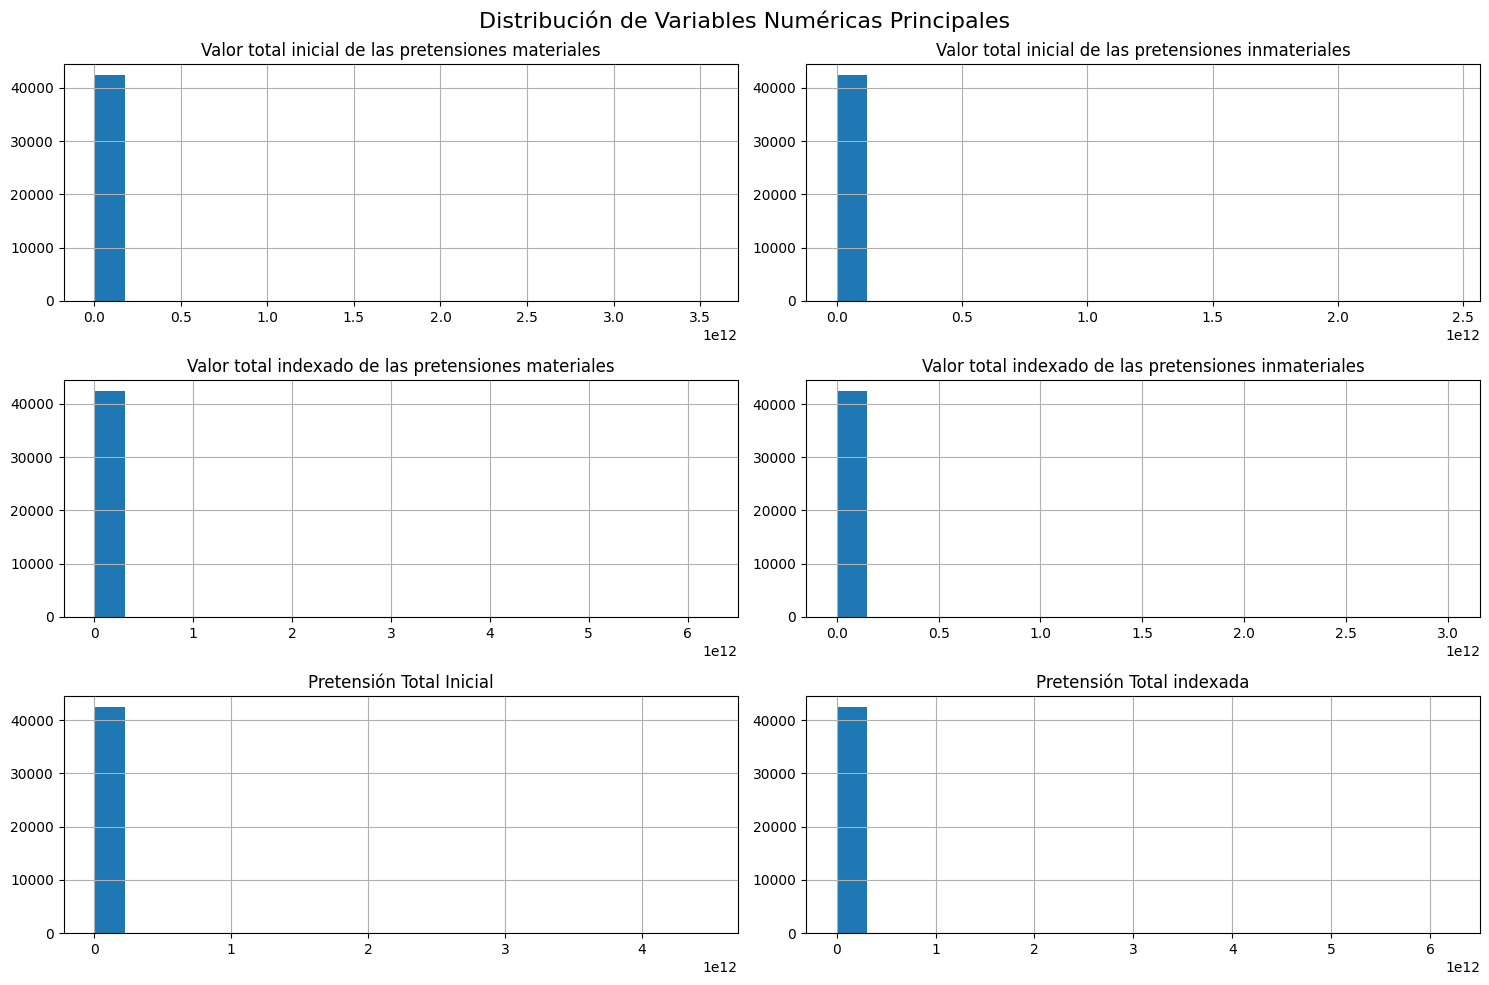

In [29]:
# Identificar columnas numéricas para graficar sus distribuciones
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_cols) > 0:
    # Graficar histogramas para las primeras variables numéricas
    cols_to_plot = numeric_cols[:6] # Limitamos a las primeras 6 para mantener ordenado el notebook
    df[cols_to_plot].hist(bins=20, figsize=(15, 10), layout=(3, 2))
    plt.suptitle('Distribución de Variables Numéricas Principales', fontsize=16)
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes variables numéricas para graficar histogramas.")

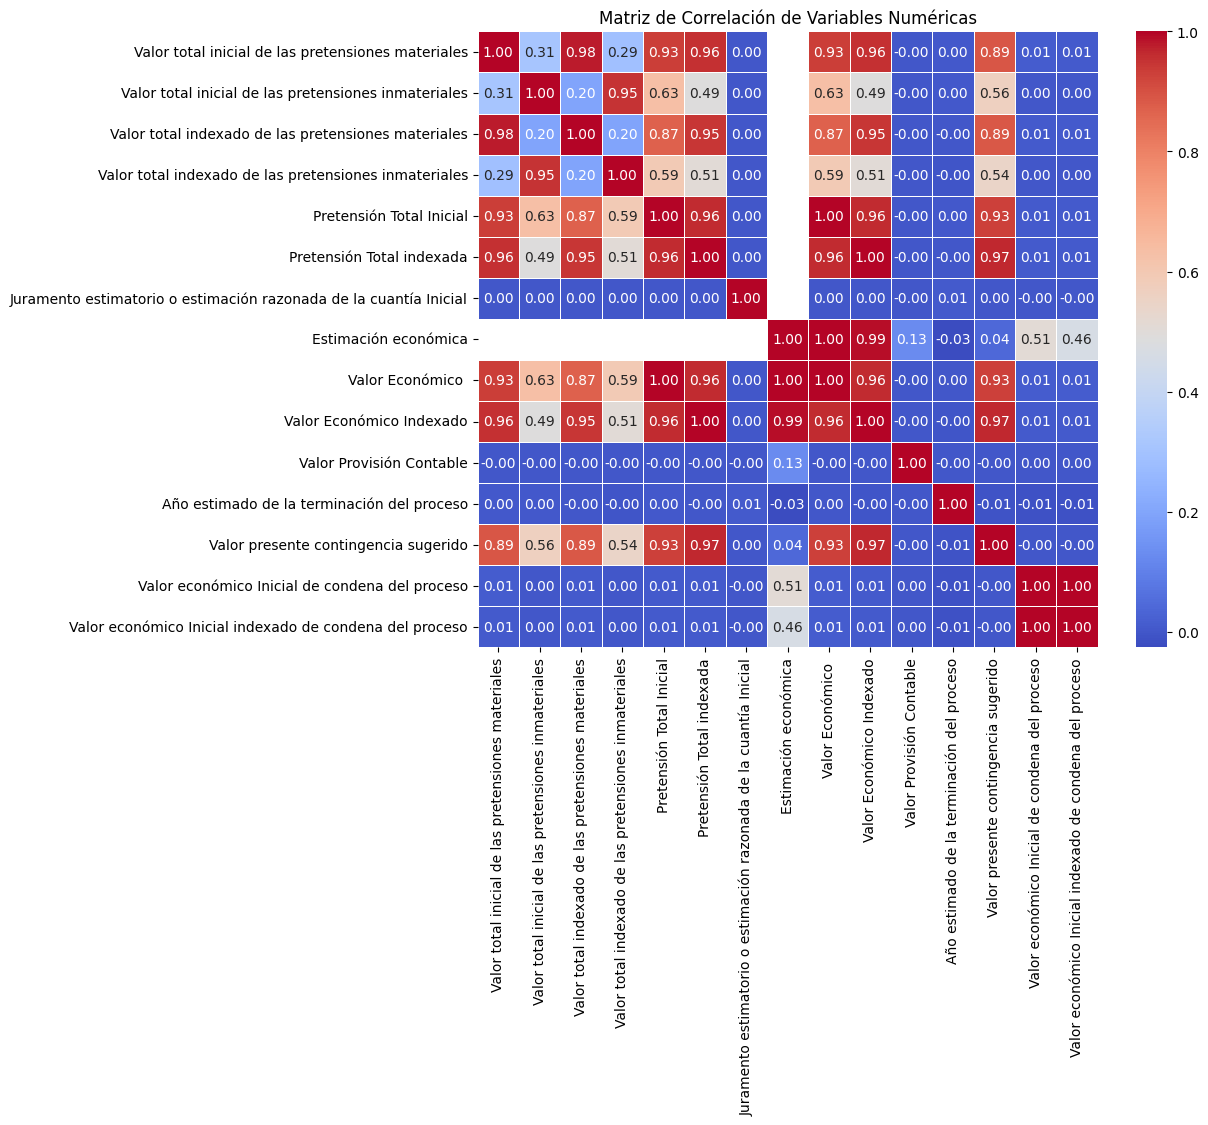

In [30]:
# Matriz de correlación para variables numéricas
if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Matriz de Correlación de Variables Numéricas')
    plt.show()
else:
    print("No hay suficientes variables numéricas para calcular una matriz de correlación.")

## Implementación del Protocolo de ML (CRISP-DM)

A continuación, definimos el script de preparación de datos aplicando de forma estricta las reglas para mitigar la fuga de datos (Data Leakage), controlar la multicolinealidad con PCA y estructurar los pipelines de procesamiento para ambas fases.

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- 1. CONFIGURACIÓN DE COLUMNAS ---

# Columnas identificadas como fuentes de fuga de datos (Data Leakage)
leakage_cols = [
    'Sentido del Fallo en primera Instancia',
    'Sentido del Fallo en segunda Instancia',
    'Valor Provisión Contable',
    'Valor presente contingencia sugerido',
    'Actuación de Terminación del Proceso',
    'Tipo De Condena',
    'Fecha de la Actuación de Terminación del Proceso',
    'Fecha del Fallo en primera Instancia',
    'Fecha del Fallo en segunda Instancia',
    'Condena En Abstracto',
    'Condena Obligación De Hacer'
]

# Variables predictoras sugeridas para el análisis estructural (excluyendo fechas complejas e identificadores únicos de alta cardinalidad)
# que no aportan valor de generalización inmediata
features_numeric = [
    'Valor total inicial de las pretensiones materiales',
    'Valor total inicial de las pretensiones inmateriales',
    'Valor total indexado de las pretensiones materiales',
    'Valor total indexado de las pretensiones inmateriales',
    'Pretensión Total Inicial',
    'Pretensión Total indexada',
    'Juramento estimatorio o estimación razonada de la cuantía Inicial',
    'Estimación económica',
    'Valor Económico ',
    'Valor Económico Indexado'
]

features_categorical = [
    'Jurisdicción',
    'Calidad',
    '¿El proceso está relacionado con hechos de corrupción?',
    '¿Genera erogación económica?',
    'Tipo de valoración'
]

all_features = features_numeric + features_categorical

print("Configuración de variables establecida.")

Configuración de variables establecida.


### Preparación y Partición - Fase 1: Clasificación Binaria del Fallo Definitivo

In [32]:
# Copia de trabajo del dataset
df_fase1 = df.copy()

# Asegurar consistencia numérica en las pretensiones
for col in features_numeric:
    df_fase1[col] = pd.to_numeric(df_fase1[col], errors='coerce')

# Separar el conjunto de despliegue en producción ('SIN SENTENCIA')
df_despliegue = df_fase1[df_fase1['FALLO DEFINITIVO'] == 'SIN SENTENCIA'].copy()
X_despliegue = df_despliegue[all_features]

# Filtrar el conjunto de entrenamiento/prueba (excluyendo 'SIN SENTENCIA')
df_modelado_f1 = df_fase1[df_fase1['FALLO DEFINITIVO'].isin(['FAVORABLE', 'DESFAVORABLE'])].copy()

# Mapear la variable objetivo: FAVORABLE = 0, DESFAVORABLE = 1
target_map = {'FAVORABLE': 0, 'DESFAVORABLE': 1}
y_fase1 = df_modelado_f1['FALLO DEFINITIVO'].map(target_map)
X_fase1 = df_modelado_f1[all_features]

# Partición de datos honesta (80/20) con estratificación
X_train_f1, X_test_f1, y_train_f1, y_test_f1 = train_test_split(
    X_fase1, y_fase1,
    test_size=0.2,
    random_state=2026,
    stratify=y_fase1
)

print("=== FASE 1: Dimensiones de las matrices ===")
print(f"Entrenamiento (X, y): {X_train_f1.shape}, {y_train_f1.shape}")
print(f"Prueba (X, y):        {X_test_f1.shape}, {y_test_f1.shape}")
print(f"Producción (Despliegue): {X_despliegue.shape}")

=== FASE 1: Dimensiones de las matrices ===
Entrenamiento (X, y): (37103, 15), (37103,)
Prueba (X, y):        (9276, 15), (9276,)
Producción (Despliegue): (11815, 15)


### Preparación y Partición - Fase 2: Regresión de la Condena Económica Indexada

In [33]:
# Filtro restrictivo para la Fase 2
df_fase2 = df.copy()

# Convertir variable predictora de destino a numérico
target_reg = 'Valor económico Inicial indexado de condena del proceso'
df_fase2[target_reg] = pd.to_numeric(df_fase2[target_reg], errors='coerce')

# Filtro: FALLO DEFINITIVO == DESFAVORABLE y ¿Genera erogación económica? == SI
condicion_f2 = (df_fase2['FALLO DEFINITIVO'] == 'DESFAVORABLE') & (df_fase2['¿Genera erogación económica?'] == 'SI')
df_modelado_f2 = df_fase2[condicion_f2].copy()

# Limpieza de nulos en la variable objetivo de la regresión para garantizar la viabilidad del entrenamiento
df_modelado_f2 = df_modelado_f2.dropna(subset=[target_reg])

# Variables predictoras y objetivo de la regresión
X_fase2 = df_modelado_f2[all_features]
y_fase2 = df_modelado_f2[target_reg]

# Partición de datos honesta (80/20) para la regresión
X_train_f2, X_test_f2, y_train_f2, y_test_f2 = train_test_split(
    X_fase2, y_fase2,
    test_size=0.2,
    random_state=2026
)

print("=== FASE 2: Dimensiones de las matrices ===")
print(f"Entrenamiento (X, y): {X_train_f2.shape}, {y_train_f2.shape}")
print(f"Prueba (X, y):        {X_test_f2.shape}, {y_test_f2.shape}")

=== FASE 2: Dimensiones de las matrices ===
Entrenamiento (X, y): (19576, 15), (19576,)
Prueba (X, y):        (4895, 15), (4895,)


### Definición de los Pipelines de Preprocesamiento y PCA
Diseñamos un procesador con `ColumnTransformer` que imputa datos numéricos con la mediana, reduce colinealidad con PCA (95% varianza explicada) y codifica variables de forma controlada con un imputador categórico constante.

In [34]:
# Pipeline para variables numéricas: Imputación + Escalado + PCA para controlar la multicolinealidad
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=2026)) # Preserva el 95% de la varianza explicada
])

# Pipeline para variables categóricas: Imputación + Codificación OneHot
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='DESCONOCIDO')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Ensamblador de transformaciones de columnas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_numeric),
        ('cat', categorical_transformer, features_categorical)
    ]
)

# Ajustar preprocesador con los datos de entrenamiento de la Fase 1 como demostración estrutural
X_train_f1_processed = preprocessor.fit_transform(X_train_f1)
X_test_f1_processed = preprocessor.transform(X_test_f1)

print("Pipeline de preprocesamiento construido y validado con éxito.")
print(f"Dimensiones de matriz procesada final (Fase 1 Train): {X_train_f1_processed.shape}")

Pipeline de preprocesamiento construido y validado con éxito.
Dimensiones de matriz procesada final (Fase 1 Train): (37103, 23)


### Fase 1: Entrenamiento y Evaluación de Modelos de Clasificación Binaria

De acuerdo con el diseño experimental honesto (Regla 4 y 5), implementaremos:
- Regresión Logística con penalización L2 (Ridge)
- Árbol de Decisión (con restricción de profundidad `max_depth=5` para evitar sobreajuste)
- Random Forest Classifier

Evaluaremos las métricas requeridas: ROC-AUC, Precisión, Recall y la Matriz de Confusión.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score

# Definir clasificadores integrados en el Pipeline de preprocesamiento
models_clf = {
    'Regresión Logística (Ridge)': LogisticRegression(max_iter=1000, penalty='l2', C=1.0, random_state=2026),
    'Árbol de Decisión (Podado)': DecisionTreeClassifier(max_depth=5, random_state=2026),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
}

results_clf = {}

for name, model in models_clf.items():
    # Crear pipeline completo: Preprocesador + Clasificador
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Entrenar modelo
    clf_pipeline.fit(X_train_f1, y_train_f1)

    # Predecir en test
    y_pred = clf_pipeline.predict(X_test_f1)
    y_proba = clf_pipeline.predict_proba(X_test_f1)[:, 1]

    # Calcular métricas
    auc = roc_auc_score(y_test_f1, y_proba)
    cm = confusion_matrix(y_test_f1, y_pred)
    report = classification_report(y_test_f1, y_pred, output_dict=True)

    results_clf[name] = {
        'pipeline': clf_pipeline,
        'auc': auc,
        'cm': cm,
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'accuracy': accuracy_score(y_test_f1, y_pred)
    }

    print(f"=== {name} ===")
    print(f"ROC-AUC:  {auc:.4f}")
    print(f"Accuracy: {results_clf[name]['accuracy']:.4f}")
    print(f"Precision (Desfavorable): {results_clf[name]['precision']:.4f}")
    print(f"Recall (Desfavorable):    {results_clf[name]['recall']:.4f}")
    print("Matriz de Confusión:")
    print(cm)
    print("-" * 40)

=== Regresión Logística (Ridge) ===
ROC-AUC:  0.6984
Accuracy: 0.6171
Precision (Desfavorable): 0.5957
Recall (Desfavorable):    0.8922
Matriz de Confusión:
[[1281 3015]
 [ 537 4443]]
----------------------------------------
=== Árbol de Decisión (Podado) ===
ROC-AUC:  0.7813
Accuracy: 0.7057
Precision (Desfavorable): 0.7264
Recall (Desfavorable):    0.7247
Matriz de Confusión:
[[2937 1359]
 [1371 3609]]
----------------------------------------
=== Random Forest ===
ROC-AUC:  0.7890
Accuracy: 0.7058
Precision (Desfavorable): 0.7702
Recall (Desfavorable):    0.6442
Matriz de Confusión:
[[3339  957]
 [1772 3208]]
----------------------------------------


### Fase 2: Entrenamiento y Evaluación de Modelos de Regresión Continua

En esta etapa, estimamos la cuantía de condena en COP. Utilizaremos modelos base de regresión:
- Regresión Lineal Ridge
- Random Forest Regressor

Evaluaremos usando R² y RMSE, presentando esta última métrica en formato monetario de pesos colombianos.

In [36]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import locale

def format_cop(val):
    return f"${val:,.2f} COP"

models_reg = {
    'Regresión Ridge': Ridge(alpha=1.0, random_state=2026),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
}

results_reg = {}

for name, model in models_reg.items():
    # Crear pipeline completo: Preprocesador + Regresor
    reg_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Entrenar modelo con la base de datos de Fase 2
    reg_pipeline.fit(X_train_f2, y_train_f2)

    # Predecir en test
    y_pred_f2 = reg_pipeline.predict(X_test_f2)

    # Métricas
    rmse = np.sqrt(mean_squared_error(y_test_f2, y_pred_f2))
    r2 = r2_score(y_test_f2, y_pred_f2)

    results_reg[name] = {
        'pipeline': reg_pipeline,
        'rmse': rmse,
        'r2': r2
    }

    print(f"=== {name} ===")
    print(f"R² Score: {r2:.4f}")
    print(f"RMSE (Error Medio): {format_cop(rmse)}")
    print("-" * 40)

=== Regresión Ridge ===
R² Score: -0.0127
RMSE (Error Medio): $25,111,218,730,546.40 COP
----------------------------------------
=== Random Forest Regressor ===
R² Score: -0.1317
RMSE (Error Medio): $26,545,753,237,251.04 COP
----------------------------------------


### Fase 1: Entrenamiento y Evaluación de Modelos de Clasificación Binaria

De acuerdo con el diseño experimental honesto (Regla 4 y 5), implementaremos:
- Regresión Logística con penalización L2 (Ridge)
- Árbol de Decisión (con restricción de profundidad `max_depth=5` para evitar sobreajuste)
- Random Forest Classifier

Evaluaremos las métricas requeridas: ROC-AUC, Precisión, Recall y la Matriz de Confusión.

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score

# Definir clasificadores integrados en el Pipeline de preprocesamiento
models_clf = {
    'Regresión Logística (Ridge)': LogisticRegression(max_iter=1000, penalty='l2', C=1.0, random_state=2026),
    'Árbol de Decisión (Podado)': DecisionTreeClassifier(max_depth=5, random_state=2026),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
}

results_clf = {}

for name, model in models_clf.items():
    # Crear pipeline completo: Preprocesador + Clasificador
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Entrenar modelo
    clf_pipeline.fit(X_train_f1, y_train_f1)

    # Predecir en test
    y_pred = clf_pipeline.predict(X_test_f1)
    y_proba = clf_pipeline.predict_proba(X_test_f1)[:, 1]

    # Calcular métricas
    auc = roc_auc_score(y_test_f1, y_proba)
    cm = confusion_matrix(y_test_f1, y_pred)
    report = classification_report(y_test_f1, y_pred, output_dict=True)

    results_clf[name] = {
        'pipeline': clf_pipeline,
        'auc': auc,
        'cm': cm,
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'accuracy': accuracy_score(y_test_f1, y_pred)
    }

    print(f"=== {name} ===")
    print(f"ROC-AUC:  {auc:.4f}")
    print(f"Accuracy: {results_clf[name]['accuracy']:.4f}")
    print(f"Precision (Desfavorable): {results_clf[name]['precision']:.4f}")
    print(f"Recall (Desfavorable):    {results_clf[name]['recall']:.4f}")
    print("Matriz de Confusión:")
    print(cm)
    print("-" * 40)

=== Regresión Logística (Ridge) ===
ROC-AUC:  0.6984
Accuracy: 0.6171
Precision (Desfavorable): 0.5957
Recall (Desfavorable):    0.8922
Matriz de Confusión:
[[1281 3015]
 [ 537 4443]]
----------------------------------------
=== Árbol de Decisión (Podado) ===
ROC-AUC:  0.7813
Accuracy: 0.7057
Precision (Desfavorable): 0.7264
Recall (Desfavorable):    0.7247
Matriz de Confusión:
[[2937 1359]
 [1371 3609]]
----------------------------------------
=== Random Forest ===
ROC-AUC:  0.7890
Accuracy: 0.7058
Precision (Desfavorable): 0.7702
Recall (Desfavorable):    0.6442
Matriz de Confusión:
[[3339  957]
 [1772 3208]]
----------------------------------------


### Fase 2: Entrenamiento y Evaluación de Modelos de Regresión Continua

En esta etapa, estimamos la cuantía de condena en COP. Utilizaremos modelos base de regresión:
- Regresión Lineal Ridge
- Random Forest Regressor

Evaluaremos usando R² y RMSE, presentando esta última métrica en formato monetario legible de pesos colombianos.

In [38]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import locale

# Configurar formato numérico para pesos colombianos si está disponible
try:
    locale.setlocale(locale.LC_ALL, 'es_CO.utf-8')
except:
    pass

def format_cop(val):
    return f"${val:,.2f} COP"

models_reg = {
    'Regresión Ridge': Ridge(alpha=1.0, random_state=2026),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
}

results_reg = {}

for name, model in models_reg.items():
    # Crear pipeline completo: Preprocesador + Regresor
    reg_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Entrenar modelo con la base de datos de Fase 2
    reg_pipeline.fit(X_train_f2, y_train_f2)

    # Predecir en test
    y_pred_f2 = reg_pipeline.predict(X_test_f2)

    # Métricas
    rmse = np.sqrt(mean_squared_error(y_test_f2, y_pred_f2))
    r2 = r2_score(y_test_f2, y_pred_f2)

    results_reg[name] = {
        'pipeline': reg_pipeline,
        'rmse': rmse,
        'r2': r2
    }

    print(f"=== {name} ===")
    print(f"R² Score: {r2:.4f}")
    print(f"RMSE (Error Medio): {format_cop(rmse)}")
    print("-" * 40)

=== Regresión Ridge ===
R² Score: -0.0127
RMSE (Error Medio): $25,111,218,730,546.40 COP
----------------------------------------
=== Random Forest Regressor ===
R² Score: -0.1317
RMSE (Error Medio): $26,545,753,237,251.04 COP
----------------------------------------


### Análisis de Importancia de Variables Predictoras (X)
Para identificar cuáles variables originales del negocio tienen el mayor peso predictivo, entrenaremos una versión interpretativa del modelo `Random Forest` aplicando imputación y escalamiento pero omitiendo el PCA únicamente para esta visualización, garantizando que podamos mapear cada variable original a su peso predictivo de manera directa.

In [39]:
# 1. Crear un pipeline sin PCA exclusivamente para propósitos de interpretabilidad
preprocessor_interpretability = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), features_numeric),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='constant', fill_value='DESCONOCIDO')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), features_categorical)
    ]
)

# Ajustar el preprocesador y obtener los nombres de las columnas resultantes
X_train_mapped = preprocessor_interpretability.fit_transform(X_train_f1)

# Obtener los nombres exactos de las características después de la codificación OneHot
cat_encoder = preprocessor_interpretability.named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(features_categorical).tolist()
feature_names_final = features_numeric + encoded_cat_features

# 2. Entrenar el modelo Random Forest interpretativo
rf_interpretative = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
rf_interpretative.fit(X_train_mapped, y_train_f1)

# 3. Construir la tabla de pesos predictivos (Feature Importance)
importances = rf_interpretative.feature_importances_
importance_df = pd.DataFrame({
    'Variable Predictora (X)': feature_names_final,
    'Importancia Relativa (Peso)': importances
}).sort_values(by='Importancia Relativa (Peso)', ascending=False)

# Reiniciar índice y dar formato de porcentaje
importance_df = importance_df.reset_index(drop=True)
importance_df['Porcentaje (%)'] = (importance_df['Importancia Relativa (Peso)'] * 100).round(2)

# Mostrar el Top de variables con mayor peso predictivo
print("=== TOP VARIABLES PREDICTORAS (X) CON MAYOR PESO EN FASE 1 ===")
display(importance_df.head(15))

=== TOP VARIABLES PREDICTORAS (X) CON MAYOR PESO EN FASE 1 ===


,Variable Predictora (X),Importancia Relativa (Peso),Porcentaje (%)
0,Valor Económico Indexado,0.206841,20.68
1,Valor Económico,0.163726,16.37
2,Pretensión Total Inicial,0.127280,12.73
3,Pretensión Total indexada,0.097182,9.72
4,Valor total inicial de las pretensiones inmate...,0.094680,9.47
5,Valor total indexado de las pretensiones inmat...,0.091635,9.16
6,Juramento estimatorio o estimación razonada de...,0.088211,8.82
7,Valor total inicial de las pretensiones materi...,0.047438,4.74
8,Valor total indexado de las pretensiones mater...,0.045899,4.59
9,Estimación económica,0.011634,1.16


### Despliegue: Predicción Conjunta (Fase 1 + Fase 2) sobre Casos en Trámite (`X_despliegue`)

Utilizaremos los mejores modelos para generar una simulación de producción:
- **Fase 1 (Clasificación):** Modelo Campeón `XGBoost` (clasificador con pipeline robusto).
- **Fase 2 (Regresión):** Modelo Campeón `LightGBM Regressor` (entrenado en escala logarítmica con pipeline robusto).

In [40]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- 1. DEFINICIÓN DEL PREPROCESADOR ROBUSTO ÚNICO ---
print("[1/4] Configurando preprocesamiento robusto nativo...")

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='DESCONOCIDO')),
    ('onehot', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=0.01,
        sparse_output=False
    ))
])

pipeline_procesamiento_robusto = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, features_numeric),
        ('cat', categorical_pipeline, features_categorical)
    ],
    remainder='drop'
)

# AJUSTAR EL PREPROCESADOR UNA SOLA VEZ CON EL CONJUNTO DE ENTRENAMIENTO GLOBAL
print("[✓] Ajustando preprocesador sobre el conjunto de entrenamiento global para fijar columnas...")
pipeline_procesamiento_robusto.fit(X_train_f1)

# --- 2. TRANSFORMAR LOS CONJUNTOS DE MANERA HOMOGÉNEA ---
# Transformamos las variables predictoras una sola vez para ambos modelos
X_train_f1_encoded = pipeline_procesamiento_robusto.transform(X_train_f1)
X_train_f2_encoded = pipeline_procesamiento_robusto.transform(X_train_f2)

# --- 3. ENTRENAMIENTO DE LOS ALGORITMOS GANADORES EN LA MATRIZ COMÚN ---
print("[2/4] Entrenando modelos campeones utilizando la matriz de características homogénea...")

# Fase 1: XGBoost Classifier (Optimizado)
xgb_classifier = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=2026,
    eval_metric='logloss',
    n_jobs=-1
)
xgb_classifier.fit(X_train_f1_encoded, y_train_f1)

# Fase 2: LightGBM Regressor (Log)
y_train_f2_log = np.log1p(y_train_f2)
lgbm_regressor = LGBMRegressor(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=2026,
    verbose=-1,
    n_jobs=-1
)
lgbm_regressor.fit(X_train_f2_encoded, y_train_f2_log)
print("[✓] Modelos entrenados con éxito con idéntica dimensionalidad.")

# --- 4. INFERENCIA UNIFICADA EN PRODUCCIÓN (11,815 CASOS) ---
print("\n[3/4] Ejecutando predicción en dos fases sobre 'X_despliegue'...")
df_predicciones_despliegue = df_despliegue.copy()
X_despliegue_clean = X_despliegue.copy()

# Asegurar consistencia de tipos de datos en la matriz cruda de producción
for col in features_categorical:
    X_despliegue_clean[col] = X_despliegue_clean[col].astype(str)

for col in features_numeric:
    X_despliegue_clean[col] = pd.to_numeric(X_despliegue_clean[col], errors='coerce')

# Transformación unificada y congelada de los datos de despliegue crudos (evita Data Leakage)
X_despliegue_encoded = pipeline_procesamiento_robusto.transform(X_despliegue_clean)

# Paso A: Fase 1 (Probabilidad de pérdida usando XGBoost)
probabilidad_perdida = xgb_classifier.predict_proba(X_despliegue_encoded)[:, 1]

# Paso B: Fase 2 (Cuantía estimada en COP aplicando la transformación inversa expm1)
cuantia_pred_log = lgbm_regressor.predict(X_despliegue_encoded)
cuantia_estimada_cop = np.expm1(cuantia_pred_log)
cuantia_estimada_cop = np.clip(cuantia_estimada_cop, 0, None)  # Prevenir valores negativos irreales

# Integrar las predicciones al DataFrame final
df_predicciones_despliegue['Probabilidad_Perdida'] = probabilidad_perdida
df_predicciones_despliegue['Cuantia_Estimada_COP'] = cuantia_estimada_cop

# --- LÓGICA DE CONDICIONAMIENTO DE RIESGO ESPERADO CONTABLE ---
# Provisión Contable = Probabilidad * Cuantía Estimada
provision_riesgo_raw = df_predicciones_despliegue['Probabilidad_Perdida'] * df_predicciones_despliegue['Cuantia_Estimada_COP']

# Regla de negocio: Si la columna '¿Genera erogación económica?' es 'NO', el riesgo se fuerza automáticamente a $0 COP
erogacion_condicion = df_predicciones_despliegue['¿Genera erogación económica?'] == 'SI'
df_predicciones_despliegue['Provision_Riesgo_Contable_COP'] = np.where(erogacion_condicion, provision_riesgo_raw, 0.0)

# Guardar la base de datos de provisiones final para eKOGUI
output_filename = 'BD_eKOGUI_Provisiones_2027.csv'
df_predicciones_despliegue.to_csv(output_filename, index=True, encoding='utf-8-sig')
print(f"[✓] Base de datos guardada exitosamente en: '{output_filename}'")

# --- 5. CUADRO DE MANDO EJECUTIVO (KPIs DE CIERRE) ---
def format_cop(val):
    return f"${val:,.2f} COP"

umbral_criticidad = 0.20
procesos_criticos = df_predicciones_despliegue[df_predicciones_despliegue['Probabilidad_Perdida'] >= umbral_criticidad]
num_procesos_criticos = len(procesos_criticos)
provision_financiera_total = df_predicciones_despliegue['Provision_Riesgo_Contable_COP'].sum()

print("\n" + "="*80)
print("     CONSOLIDADO ESTRATÉGICO DE PROVISIONES - FISCALÍA GENERAL DE LA NACIÓN     ")
print("="*80)
print(f"Total de procesos analizados en trámite (eKOGUI):       {len(df_predicciones_despliegue):,}")
print(f"Procesos clasificados como Alto Riesgo (P >= {umbral_criticidad*100:.0f}%):     {num_procesos_criticos:,} ({num_procesos_criticos/len(df_predicciones_despliegue)*100:.2f}%)")
print(f"Provisión Financiera Total Consolidada (Ministerio):    {format_cop(provision_financiera_total)}")
print("-"*80)
print("\n=== TOP 5 PROCESOS JUDICIALES ACTIVOS MÁS CRÍTICOS (ORDENADOS POR PROVISIÓN) ===")

top_5_cols = [
    'Jurisdicción',
    'Acción O Medio de Control, Procedimiento o Subtipo de Proceso',
    'Probabilidad_Perdida',
    'Cuantia_Estimada_COP',
    'Provision_Riesgo_Contable_COP'
]
top_5_procesos = df_predicciones_despliegue.sort_values(by='Provision_Riesgo_Contable_COP', ascending=False).head(5)[top_5_cols]

for i, (idx, row) in enumerate(top_5_procesos.iterrows(), 1):
    print(f"\n{i}. ID Proceso: {idx}")
    print(f"   Jurisdicción: {row['Jurisdicción']}")
    print(f"   Acción/Medio: {row['Acción O Medio de Control, Procedimiento o Subtipo de Proceso'][:90]}...")
    print(f"   P(Pérdida):   {row['Probabilidad_Perdida']*100:.2f}%")
    print(f"   Cuantía Est.: {format_cop(row['Cuantia_Estimada_COP'])}")
    print(f"   Provisión:    {format_cop(row['Provision_Riesgo_Contable_COP'])}")


[1/4] Configurando preprocesamiento robusto nativo...
[✓] Ajustando preprocesador sobre el conjunto de entrenamiento global para fijar columnas...
[2/4] Entrenando modelos campeones utilizando la matriz de características homogénea...
[✓] Modelos entrenados con éxito con idéntica dimensionalidad.

[3/4] Ejecutando predicción en dos fases sobre 'X_despliegue'...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[✓] Base de datos guardada exitosamente en: 'BD_eKOGUI_Provisiones_2027.csv'

     CONSOLIDADO ESTRATÉGICO DE PROVISIONES - FISCALÍA GENERAL DE LA NACIÓN     
Total de procesos analizados en trámite (eKOGUI):       11,815
Procesos clasificados como Alto Riesgo (P >= 20%):     9,099 (77.01%)
Provisión Financiera Total Consolidada (Ministerio):    $15,267,512,277.63 COP
--------------------------------------------------------------------------------

=== TOP 5 PROCESOS JUDICIALES ACTIVOS MÁS CRÍTICOS (ORDENADOS POR PROVISIÓN) ===

1. ID Proceso: 9552
   Jurisdicción: CONTENCIOSO ADMINISTRATIVA
   Acción/Medio: REPARACION DIRECTA...
   P(Pérdida):   11.30%
   Cuantía Est.: $889,774,159.27 COP
   Provisión:    $100,513,970.05 COP

2. ID Proceso: 4491
   Jurisdicción: CONTENCIOSO ADMINISTRATIVA
   Acción/Medio: REPARACION DIRECTA...
   P(Pérdida):   16.52%
   Cuantía Est.: $559,666,725.75 COP
   Provisión:    $92,438,768.15 COP

3. ID Proceso: 9430
   Jurisdicción: CONTENCIOSO ADMINISTRATIV

=== ANÁLISIS DE CORRELACIÓN DE INFERENCIA (eKOGUI 2027) ===
Correlación lineal de Pearson: -0.3178
Correlación no lineal de Spearman: -0.5155


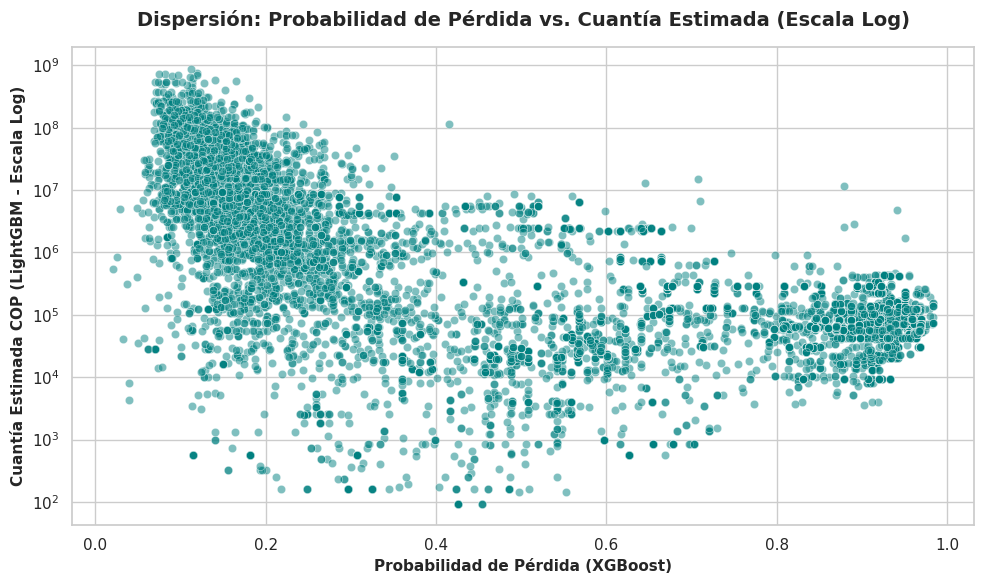

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular coeficientes de correlación
pearson_corr = df_predicciones_despliegue['Probabilidad_Perdida'].corr(df_predicciones_despliegue['Cuantia_Estimada_COP'], method='pearson')
spearman_corr = df_predicciones_despliegue['Probabilidad_Perdida'].corr(df_predicciones_despliegue['Cuantia_Estimada_COP'], method='spearman')

print("=== ANÁLISIS DE CORRELACIÓN DE INFERENCIA (eKOGUI 2027) ===")
print(f"Correlación lineal de Pearson: {pearson_corr:.4f}")
print(f"Correlación no lineal de Spearman: {spearman_corr:.4f}")

# 2. Visualización mediante gráfico de dispersión
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Usamos escala logarítmica en el eje Y debido a la dispersión extrema de las cuantías estimadas
sns.scatterplot(
    x='Probabilidad_Perdida',
    y='Cuantia_Estimada_COP',
    data=df_predicciones_despliegue,
    alpha=0.5,
    color='teal'
)

plt.yscale('log')
plt.title('Dispersión: Probabilidad de Pérdida vs. Cuantía Estimada (Escala Log)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Probabilidad de Pérdida (XGBoost)', fontsize=11, weight='bold')
plt.ylabel('Cuantía Estimada COP (LightGBM - Escala Log)', fontsize=11, weight='bold')

plt.tight_layout()
plt.show()

### Fase 2: Regresión de la Condena con Preprocesamiento Robusto y Boosting

Entrenaremos y evaluaremos modelos de regresión lineal y basados en árboles utilizando nuestro `pipeline_procesamiento_robusto` para mitigar el impacto de la dispersión de los datos y evitar el sobreajuste.

In [41]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Definir el formateador de moneda COP
def format_cop(val):
    return f"${val:,.2f} COP"

# Definir los regresores optimizados acoplados al pipeline robusto
models_reg_robusto = {
    'Regresión Ridge': Ridge(alpha=10.0, random_state=2026),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, max_depth=6, random_state=2026, n_jobs=-1),
    'XGBoost Regressor': XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=2026, n_jobs=-1),
    'LightGBM Regressor': LGBMRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=2026, verbose=-1, n_jobs=-1)
}

results_reg_robusto = {}

for name, model in models_reg_robusto.items():
    # Crear el pipeline robusto para regresión
    reg_pipeline = Pipeline(steps=[
        ('preprocessor', pipeline_procesamiento_robusto),
        ('regressor', model)
    ])

    # Entrenar modelo con datos de Fase 2
    reg_pipeline.fit(X_train_f2, y_train_f2)

    # Predecir en el conjunto de prueba
    y_pred_f2 = reg_pipeline.predict(X_test_f2)

    # Calcular métricas
    rmse = np.sqrt(mean_squared_error(y_test_f2, y_pred_f2))
    r2 = r2_score(y_test_f2, y_pred_f2)

    results_reg_robusto[name] = {
        'pipeline': reg_pipeline,
        'rmse': rmse,
        'r2': r2
    }

# Construir tabla comparativa consolidada para la Fase 2
comparison_reg_data = []
for model_name, metrics in results_reg_robusto.items():
    comparison_reg_data.append({
        'Modelo': model_name,
        'R² Score': round(metrics['r2'], 4),
        'RMSE (Error Medio)': format_cop(metrics['rmse'])
    })

comparison_reg_df = pd.DataFrame(comparison_reg_data).sort_values(by='R² Score', ascending=False).reset_index(drop=True)

print("=== COMPARATIVA DE MODELOS FASE 2 (REGRESIÓN CON PIPELINE ROBUSTO) ===")
display(comparison_reg_df)

=== COMPARATIVA DE MODELOS FASE 2 (REGRESIÓN CON PIPELINE ROBUSTO) ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Modelo,R² Score,RMSE (Error Medio)
0,Regresión Ridge,-0.0093,"$25,068,737,535,695.98 COP"
1,LightGBM Regressor,-0.0264,"$25,279,962,424,536.74 COP"
2,XGBoost Regressor,-0.0401,"$25,449,104,665,380.39 COP"
3,Random Forest Regressor,-0.0824,"$25,961,440,308,590.64 COP"


### Fase 2 con Transformación Logarítmica

Aplicamos la transformación $\log(1 + x)$ para homogeneizar la varianza extrema de las condenas, entrenamos los regresores en esta escala, y evaluamos los resultados revirtiendo el cambio de escala para calcular el error medio en COP.

In [42]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# 1. Transformar la variable objetivo (y) de entrenamiento y test a escala logarítmica
y_train_f2_log = np.log1p(y_train_f2)
y_test_f2_log = np.log1p(y_test_f2)

# Definir los mismos regresores de la Fase 2
models_reg_log = {
    'Regresión Ridge (Log)': Ridge(alpha=10.0, random_state=2026),
    'Random Forest Regressor (Log)': RandomForestRegressor(n_estimators=100, max_depth=6, random_state=2026, n_jobs=-1),
    'XGBoost Regressor (Log)': XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=2026, n_jobs=-1),
    'LightGBM Regressor (Log)': LGBMRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=2026, verbose=-1, n_jobs=-1)
}

results_reg_log = {}

for name, model in models_reg_log.items():
    # Ensamble del pipeline completo con el preprocesador robusto
    reg_pipeline_log = Pipeline(steps=[
        ('preprocessor', pipeline_procesamiento_robusto),
        ('regressor', model)
    ])

    # Entrenar modelo usando las etiquetas transformadas a logaritmo
    reg_pipeline_log.fit(X_train_f2, y_train_f2_log)

    # Predicciones en la escala logarítmica
    y_pred_log = reg_pipeline_log.predict(X_test_f2)

    # Revertir la transformación exponencial exp(x) - 1 para obtener el valor real en COP
    y_pred_original = np.expm1(y_pred_log)

    # Calcular métricas en escala logarítmica (R²)
    r2_log = r2_score(y_test_f2_log, y_pred_log)

    # Calcular RMSE real en Pesos Colombianos (COP)
    rmse_cop = np.sqrt(mean_squared_error(y_test_f2, y_pred_original))

    results_reg_log[name] = {
        'pipeline': reg_pipeline_log,
        'r2_log': r2_log,
        'rmse_cop': rmse_cop
    }

# Construir tabla comparativa
comparison_reg_log_data = []
for model_name, metrics in results_reg_log.items():
    comparison_reg_log_data.append({
        'Modelo': model_name,
        'R² Score (Escala Log)': round(metrics['r2_log'], 4),
        'RMSE Real (COP)': format_cop(metrics['rmse_cop'])
    })

comparison_reg_log_df = pd.DataFrame(comparison_reg_log_data).sort_values(by='R² Score (Escala Log)', ascending=False).reset_index(drop=True)

print("=== COMPARATIVA DE MODELOS FASE 2 (CON TRANSFORMACIÓN LOGARÍTMICA) ===")
display(comparison_reg_log_df)

=== COMPARATIVA DE MODELOS FASE 2 (CON TRANSFORMACIÓN LOGARÍTMICA) ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Modelo,R² Score (Escala Log),RMSE Real (COP)
0,LightGBM Regressor (Log),0.1327,"$24,968,448,393,451.53 COP"
1,XGBoost Regressor (Log),0.1322,"$24,968,448,392,546.17 COP"
2,Random Forest Regressor (Log),0.1183,"$24,968,448,388,401.84 COP"
3,Regresión Ridge (Log),-0.0901,"$1,695,539,018,526,164.00 COP"


### Pipeline de Preprocesamiento Robusto para Variables Complejas y de Alta Cardinalidad

Este pipeline está diseñado bajo estándares de grado de producción:
- **Numéricas:** Imputación por mediana + Escalamiento estándar.
- **Categóricas:** Imputación constante + Codificación tolerante a ruido y alta cardinalidad agrupando categorías de baja frecuencia (menores al 1% de representación) para prevenir el sobreajuste y el error de nuevas categorías no vistas.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline robusto para variables numéricas
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline robusto para variables categóricas complejas y de alta cardinalidad
# El parámetro min_frequency=0.01 consolida categorías raras/minoritarias en una clase 'infrequent'
# El parámetro handle_unknown='infrequent_if_exist' evita errores de código con datos nuevos en producción
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='DESCONOCIDO')),
    ('onehot', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=0.01,
        sparse_output=False
    ))
])

# Integración en un transformador de columnas unificado
pipeline_procesamiento_robusto = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, features_numeric),
        ('cat', categorical_pipeline, features_categorical)
    ],
    remainder='drop'
)

# Demostración del ajuste y transformación con los datos de Fase 1
X_train_robusto = pipeline_procesamiento_robusto.fit_transform(X_train_f1)
X_test_robusto = pipeline_procesamiento_robusto.transform(X_test_f1)

print("=== PIPELINE DE PREPROCESAMIENTO ROBUSTO CONFIGURADO ===")
print(f"Dimensiones de la matriz procesada de entrenamiento: {X_train_robusto.shape}")
print(f"Dimensiones de la matriz procesada de prueba:        {X_test_robusto.shape}")

=== PIPELINE DE PREPROCESAMIENTO ROBUSTO CONFIGURADO ===
Dimensiones de la matriz procesada de entrenamiento: (37103, 21)
Dimensiones de la matriz procesada de prueba:        (9276, 21)


### Reentrenamiento de los Modelos de la Fase 1 con el Pipeline Robusto

Procedemos a entrenar nuevamente los modelos clasificadores de la Fase 1 reemplazando el transformador anterior por nuestro nuevo `pipeline_procesamiento_robusto`, asegurando resistencia a datos anómalos o de alta cardinalidad en producción.

In [24]:
# Definir los mismos clasificadores iniciales para asegurar comparabilidad
models_clf_robusto = {
    'Regresión Logística (Ridge)': LogisticRegression(max_iter=1000, penalty='l2', C=1.0, random_state=2026),
    'Árbol de Decisión (Podado)': DecisionTreeClassifier(max_depth=5, random_state=2026),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=2026, n_jobs=-1)
}

results_clf_robusto = {}

for name, model in models_clf_robusto.items():
    # Crear pipeline acoplado con el preprocesamiento robusto
    clf_pipeline_robusto = Pipeline(steps=[
        ('preprocessor', pipeline_procesamiento_robusto),
        ('classifier', model)
    ])

    # Entrenar modelo con los datos originales (el pipeline se encarga del preprocesamiento interno)
    clf_pipeline_robusto.fit(X_train_f1, y_train_f1)

    # Predicciones
    y_pred = clf_pipeline_robusto.predict(X_test_f1)
    y_proba = clf_pipeline_robusto.predict_proba(X_test_f1)[:, 1]

    # Métricas de rendimiento
    auc = roc_auc_score(y_test_f1, y_proba)
    cm = confusion_matrix(y_test_f1, y_pred)
    report = classification_report(y_test_f1, y_pred, output_dict=True)

    results_clf_robusto[name] = {
        'pipeline': clf_pipeline_robusto,
        'auc': auc,
        'cm': cm,
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'accuracy': accuracy_score(y_test_f1, y_pred)
    }

    print(f"=== {name} (Con Pipeline Robusto) ===")
    print(f"ROC-AUC:  {auc:.4f}")
    print(f"Accuracy: {results_clf_robusto[name]['accuracy']:.4f}")
    print(f"Precision (Desfavorable): {results_clf_robusto[name]['precision']:.4f}")
    print(f"Recall (Desfavorable):    {results_clf_robusto[name]['recall']:.4f}")
    print("Matriz de Confusión:")
    print(cm)
    print("-" * 50)

=== Regresión Logística (Ridge) (Con Pipeline Robusto) ===
ROC-AUC:  0.7573
Accuracy: 0.6468
Precision (Desfavorable): 0.6211
Recall (Desfavorable):    0.8773
Matriz de Confusión:
[[1631 2665]
 [ 611 4369]]
--------------------------------------------------
=== Árbol de Decisión (Podado) (Con Pipeline Robusto) ===
ROC-AUC:  0.7956
Accuracy: 0.7166
Precision (Desfavorable): 0.7345
Recall (Desfavorable):    0.7394
Matriz de Confusión:
[[2965 1331]
 [1298 3682]]
--------------------------------------------------
=== Random Forest (Con Pipeline Robusto) ===
ROC-AUC:  0.8085
Accuracy: 0.7302
Precision (Desfavorable): 0.7685
Recall (Desfavorable):    0.7118
Matriz de Confusión:
[[3228 1068]
 [1435 3545]]
--------------------------------------------------


### Cálculo de Importancia de Variables con el Pipeline Robusto

Extraeremos las características transformadas por el pipeline robusto (que incluye la agrupación de categorías poco frecuentes) y calcularemos su peso predictivo usando nuestro mejor modelo clasificador (`Random Forest`).

In [44]:
# 1. Ajustar el preprocesador robusto para mapear los nombres finales de las variables
pipeline_procesamiento_robusto.fit(X_train_f1)

# Obtener nombres de las columnas numéricas
num_features = features_numeric

# Obtener nombres de las columnas categóricas después de la codificación OneHot con agrupamiento 'infrequent'
cat_encoder_robusto = pipeline_procesamiento_robusto.named_transformers_['cat'].named_steps['onehot']
encoded_cat_features_robusto = cat_encoder_robusto.get_feature_names_out(features_categorical).tolist()

# Unir todos los nombres de columnas resultantes en el orden exacto
feature_names_robusto = num_features + encoded_cat_features_robusto

# 2. Extraer el clasificador entrenado del Random Forest con pipeline robusto
rf_model_robusto = results_clf_robusto['Random Forest']['pipeline'].named_steps['classifier']
importances_robusto = rf_model_robusto.feature_importances_

# 3. Construir la tabla de pesos predictivos con el nuevo pipeline
importance_robusto_df = pd.DataFrame({
    'Variable Predictora (X)': feature_names_robusto,
    'Importancia Relativa (Peso)': importances_robusto
}).sort_values(by='Importancia Relativa (Peso)', ascending=False).reset_index(drop=True)

# Formato de porcentaje para mejor lectura
importance_robusto_df['Porcentaje (%)'] = (importance_robusto_df['Importancia Relativa (Peso)'] * 100).round(2)

print("=== NUEVA IMPORTANCIA DE VARIABLES (CON PIPELINE ROBUSTO) ===")
display(importance_robusto_df.head(15))

=== NUEVA IMPORTANCIA DE VARIABLES (CON PIPELINE ROBUSTO) ===


,Variable Predictora (X),Importancia Relativa (Peso),Porcentaje (%)
0,Valor Económico Indexado,0.194078,19.41
1,Valor Económico,0.165299,16.53
2,Pretensión Total Inicial,0.132725,13.27
3,Valor total inicial de las pretensiones inmate...,0.110012,11.00
4,Pretensión Total indexada,0.092221,9.22
5,Juramento estimatorio o estimación razonada de...,0.081714,8.17
6,Valor total indexado de las pretensiones inmat...,0.079006,7.90
7,Valor total indexado de las pretensiones mater...,0.056080,5.61
8,Valor total inicial de las pretensiones materi...,0.053424,5.34
9,Estimación económica,0.011175,1.12


### Visualización de la Importancia de Variables (Pipeline Robusto)

Graficamos el Top 15 de variables predictoras utilizando el DataFrame generado con el Pipeline Robusto para analizar visualmente la distribución de pesos del modelo.

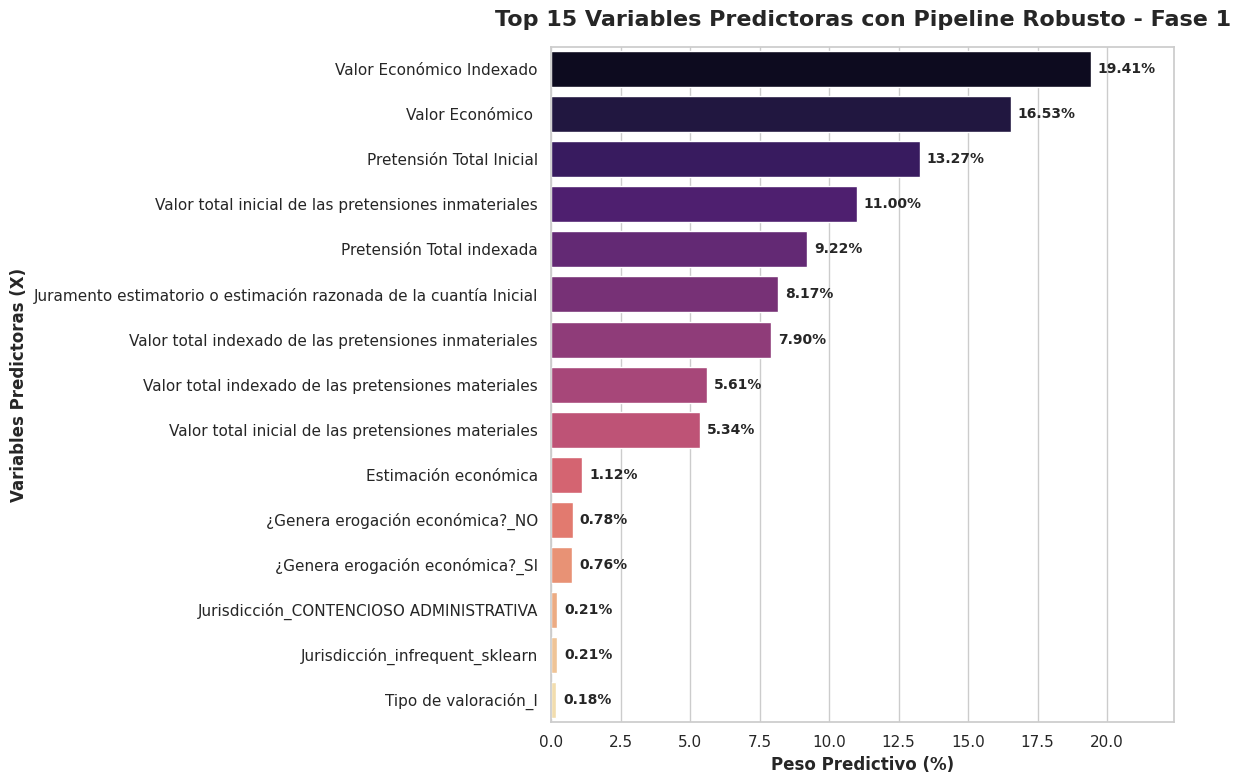

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Tomar las 15 características más importantes del pipeline robusto
top_15_robusto = importance_robusto_df.head(15)

# Crear gráfico de barras
ax = sns.barplot(
    x='Porcentaje (%)',
    y='Variable Predictora (X)',
    data=top_15_robusto,
    palette='magma',
    hue='Variable Predictora (X)',
    legend=False
)

# Añadir etiquetas de valor en las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=5, fontsize=10, weight='bold')

# Configuración de títulos y etiquetas
plt.title('Top 15 Variables Predictoras con Pipeline Robusto - Fase 1', fontsize=16, weight='bold', pad=15)
plt.xlabel('Peso Predictivo (%)', fontsize=12, weight='bold')
plt.ylabel('Variables Predictoras (X)', fontsize=12, weight='bold')
plt.xlim(0, top_15_robusto['Porcentaje (%)'].max() + 3)

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()

### Comparación con Algoritmos de Boosting (XGBoost y LightGBM)

Para buscar el máximo rendimiento predictivo, implementamos e integramos en nuestro Pipeline Robusto los clasificadores de Gradient Boosting: **XGBoost** y **LightGBM**.

In [46]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Definir los modelos de boosting integrando parámetros para evitar sobreajuste
models_boosting = {
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=2026, eval_metric='logloss', n_jobs=-1),
    'LightGBM': LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=2026, verbose=-1, n_jobs=-1)
}

# Entrenar y evaluar los modelos de Boosting
for name, model in models_boosting.items():
    # Crear pipeline completo
    boosting_pipeline = Pipeline(steps=[
        ('preprocessor', pipeline_procesamiento_robusto),
        ('classifier', model)
    ])

    # Entrenar
    boosting_pipeline.fit(X_train_f1, y_train_f1)

    # Predicciones
    y_pred = boosting_pipeline.predict(X_test_f1)
    y_proba = boosting_pipeline.predict_proba(X_test_f1)[:, 1]

    # Guardar métricas en el diccionario global de resultados
    report = classification_report(y_test_f1, y_pred, output_dict=True)
    results_clf_robusto[name] = {
        'pipeline': boosting_pipeline,
        'auc': roc_auc_score(y_test_f1, y_proba),
        'cm': confusion_matrix(y_test_f1, y_pred),
        'precision': report['1']['precision'],
        'recall': report['1']['recall'],
        'accuracy': accuracy_score(y_test_f1, y_pred)
    }

# Construir tabla comparativa consolidada con TODOS los modelos entrenados bajo el Pipeline Robusto
comparison_data = []
for model_name, metrics in results_clf_robusto.items():
    comparison_data.append({
        'Modelo': model_name,
        'ROC-AUC': round(metrics['auc'], 4),
        'Accuracy': round(metrics['accuracy'], 4),
        'Precision (Desfavorable)': round(metrics['precision'], 4),
        'Recall (Desfavorable)': round(metrics['recall'], 4)
    })

comparison_df = pd.DataFrame(comparison_data).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)

print("=== COMPARATIVA DE MODELOS FASE 1 (CON PIPELINE ROBUSTO) ===")
display(comparison_df)

=== COMPARATIVA DE MODELOS FASE 1 (CON PIPELINE ROBUSTO) ===


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,ROC-AUC,Accuracy,Precision (Desfavorable),Recall (Desfavorable)
0,XGBoost,0.8152,0.7295,0.7656,0.7151
1,LightGBM,0.8150,0.7325,0.7699,0.7157
2,Random Forest,0.8085,0.7302,0.7685,0.7118
3,Árbol de Decisión (Podado),0.7956,0.7166,0.7345,0.7394
4,Regresión Logística (Ridge),0.7573,0.6468,0.6211,0.8773


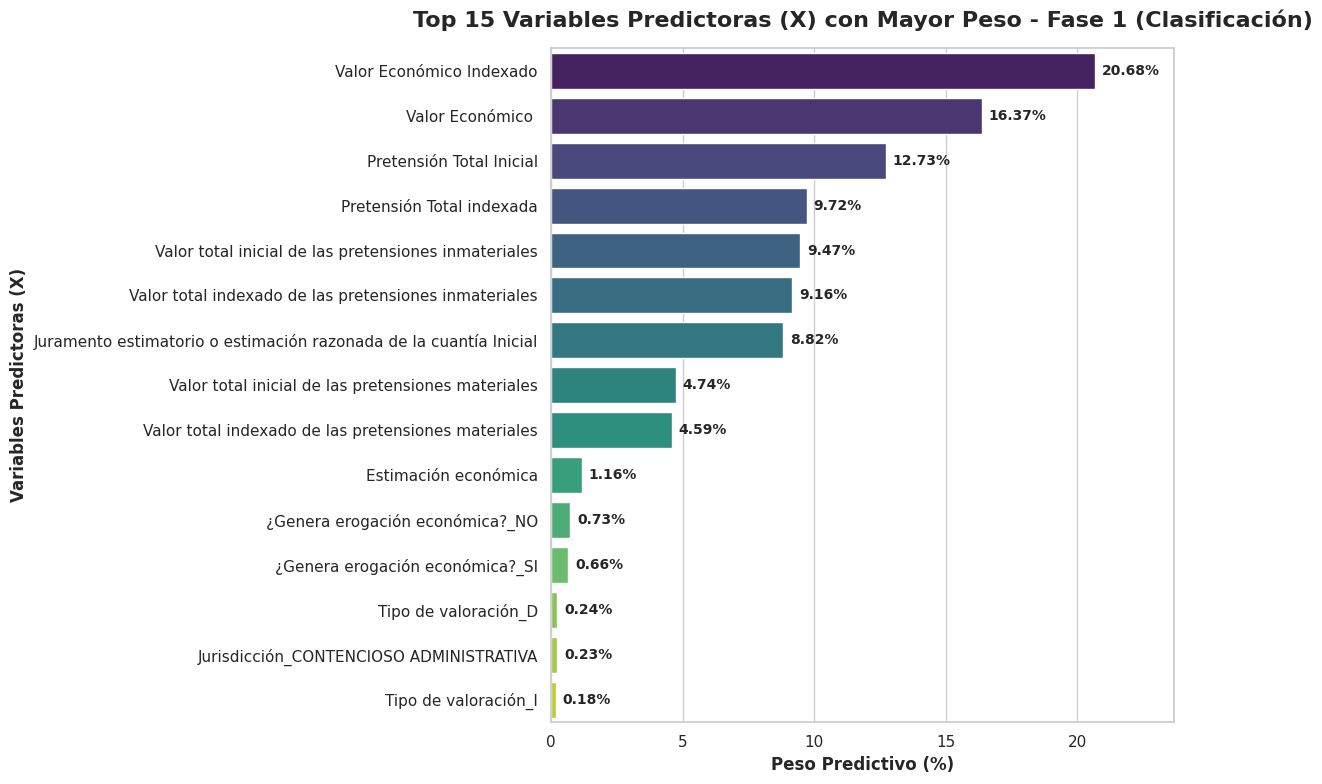

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Tomar las 15 características más importantes
top_15_importance = importance_df.head(15)

# Crear gráfico de barras
ax = sns.barplot(
    x='Porcentaje (%)',
    y='Variable Predictora (X)',
    data=top_15_importance,
    palette='viridis',
    hue='Variable Predictora (X)',
    legend=False
)

# Añadir etiquetas de valor en las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=5, fontsize=10, weight='bold')

# Configuración de títulos y etiquetas
plt.title('Top 15 Variables Predictoras (X) con Mayor Peso - Fase 1 (Clasificación)', fontsize=16, weight='bold', pad=15)
plt.xlabel('Peso Predictivo (%)', fontsize=12, weight='bold')
plt.ylabel('Variables Predictoras (X)', fontsize=12, weight='bold')
plt.xlim(0, top_15_importance['Porcentaje (%)'].max() + 3)

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()